# Visualize data

### Graphing is done to provide a fast qualitative assessment of our data, which can be useful for understanding results, finding outlier values, examinging how numbers are distributed and so on.

### Sometimes we use graphs as exploratory way. Graphs are not limited to 2D scatter plots. They can be used to explore other aspects of your data. 

In [2]:
import pandas as pd

df_students = pd.read_csv('grades.csv', delimiter=',', header='infer')

df_students = df_students.dropna(axis=0, how='any')

passes = pd.Series(df_students.Grade >= 60)

df_students = pd.concat([df_students, passes.rename('Pass')], axis=1)

df_students

,Name,StudyHours,Grade,Pass
0,Dan,10.00,50.0,False
1,Joann,11.50,50.0,False
2,Pedro,9.00,47.0,False
3,Rosie,16.00,97.0,True
4,Ethan,9.25,49.0,False
5,Vicky,1.00,3.0,False
6,Frederic,11.50,53.0,False
7,Jimmie,9.00,42.0,False
8,Rhonda,8.50,26.0,False
9,Giovanni,14.50,74.0,True


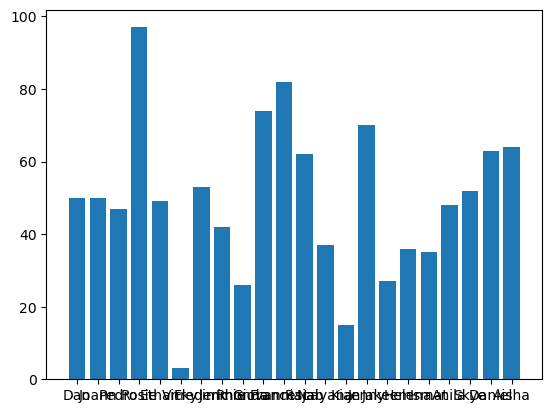

In [3]:
# Visualizing data with matplotlib

from matplotlib import pyplot as plt

plt.bar(df_students.Name, df_students.Grade)
plt.show()

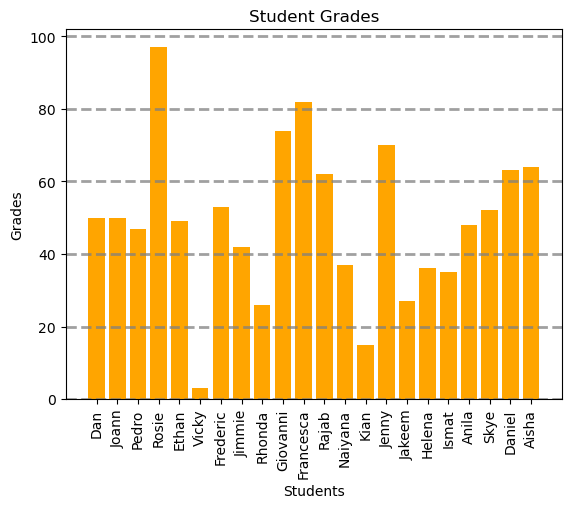

In [7]:
# improving above bar chart

plt.bar(df_students.Name, df_students.Grade, color='orange')
plt.xlabel('Students')
plt.ylabel('Grades')
plt.title('Student Grades')
plt.grid(axis='y', alpha=0.75, linewidth=2, linestyle='--', color='gray')
plt.xticks(rotation=90)

plt.show()

/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_7227/687912506.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels(df_students.Name, rotation=90)
/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_7227/687912506.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


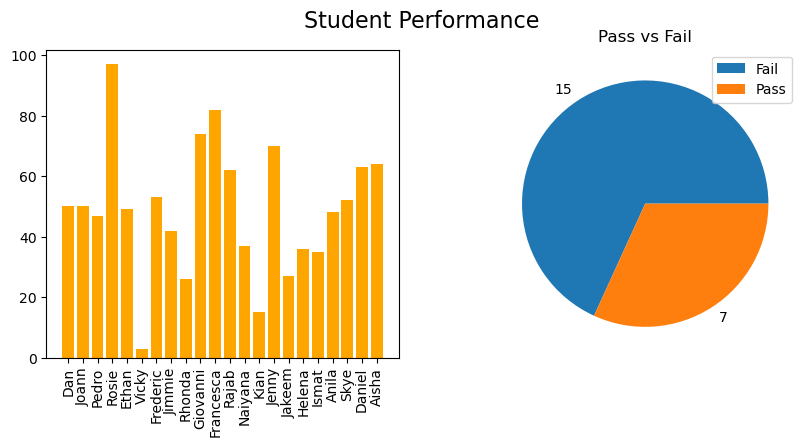

In [13]:
# Subplots using matplotlib for greater details

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].bar(df_students.Name, df_students.Grade, color='orange')
ax[0].set_xticklabels(df_students.Name, rotation=90)
pass_counts = df_students.Pass.value_counts()
ax[1].pie(pass_counts, labels=pass_counts)
ax[1].set_title('Pass vs Fail')
ax[1].legend(['Fail', 'Pass'])

fig.suptitle('Student Performance', fontsize=16)
fig.show()

/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_7227/2464097994.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


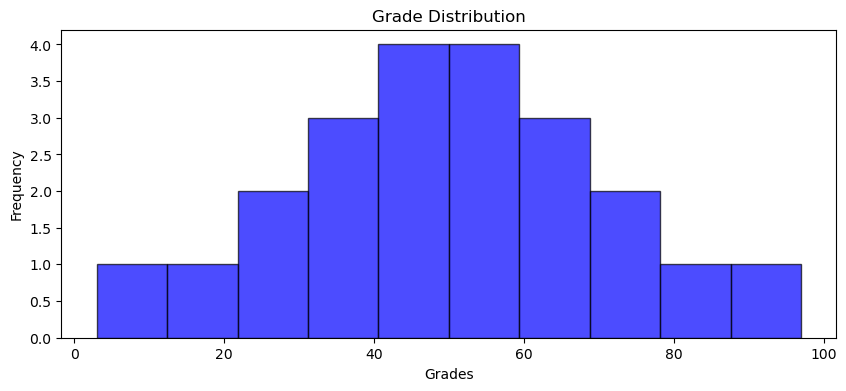

In [ ]:
# Descriptive statistics and data distribution

# Data distribution can be visualized using histograms, box plots, and scatter plots. 
# It means how the data points are spread across the range of values.
# For example, a histogram can show the frequency of grades in different ranges.

var_data = df_students['Grade']

fig = plt.figure(figsize=(10, 4))
plt.hist(var_data, bins=10, color='blue', alpha=0.7, edgecolor='black')
plt.title('Grade Distribution')
plt.xlabel('Grades')
plt.ylabel('Frequency')
fig.show()


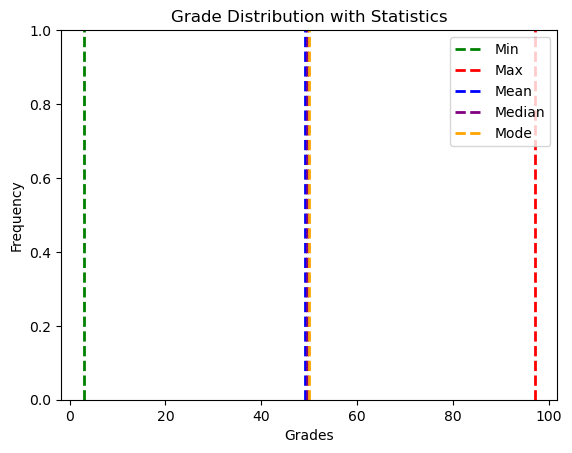

In [18]:
# Measures of central tendency and variability

# Descriptive statistics such as mean, median, mode, standard deviation, 
# and variance can be calculated to summarize the data.

var_data = df_students['Grade']
mean = var_data.mean()
median = var_data.median()
mode = var_data.mode()[0]
min_value = var_data.min()
max_value = var_data.max()

# using historgram

plt.axvline(x=min_value, color='green', linestyle='dashed', label='Min', linewidth=2)
plt.axvline(x=max_value, color='red', linestyle='dashed', label='Max', linewidth=2)
plt.axvline(x=mean, color='blue', linestyle='dashed', label='Mean', linewidth=2)
plt.axvline(x=median, color='purple', linestyle='dashed', label='Median', linewidth=2)
plt.axvline(x=mode, color='orange', linestyle='dashed', label='Mode', linewidth=2)

plt.title('Grade Distribution with Statistics')
plt.xlabel('Grades')
plt.ylabel('Frequency')
plt.legend()
plt.show()

/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_7227/3472369614.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


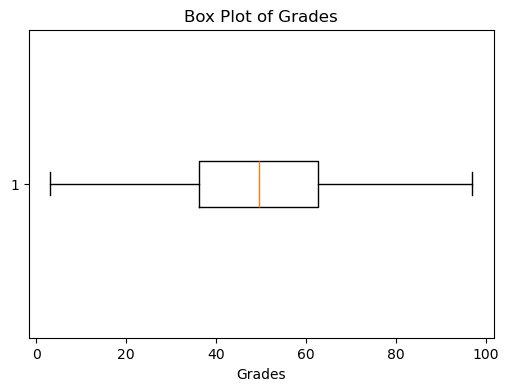

In [19]:
# using box plot

var = df_students['Grade']

fig = plt.figure(figsize=(6, 4))
plt.boxplot(var, vert=False)
plt.title('Box Plot of Grades')
plt.xlabel('Grades')
fig.show()


Min: 3.0
Max: 97.0
Mean: 49.18181818181818
Median: 49.5
Mode: 50.0


/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_7227/1874090253.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


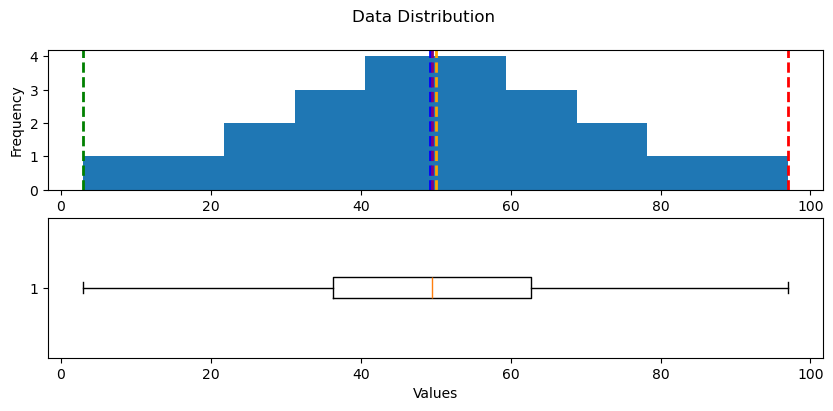

In [20]:
def show_distribution(var_data):
    from matplotlib import pyplot as plt

    min_value = var_data.min()
    max_value = var_data.max()
    mean = var_data.mean()
    median = var_data.median()
    mode = var_data.mode()[0]

    print(f'Min: {min_value}\nMax: {max_value}\nMean: {mean}\nMedian: {median}\nMode: {mode}')

    fig, ax = plt.subplots(2, 1, figsize=(10, 4))
    ax[0].hist(var_data)
    ax[0].set_ylabel('Frequency')

    ax[0].axvline(x=min_value, color='green', linestyle='dashed', label='Min', linewidth=2)    
    ax[0].axvline(x=max_value, color='red', linestyle='dashed', label='Max', linewidth=2)
    ax[0].axvline(x=mean, color='blue', linestyle='dashed', label='Mean', linewidth=2)
    ax[0].axvline(x=median, color='purple', linestyle='dashed', label='Median', linewidth=2)
    ax[0].axvline(x=mode, color='orange', linestyle='dashed', label='Mode', linewidth=2)

    ax[1].boxplot(var_data, vert=False)
    ax[1].set_xlabel('Values')
    
    fig.suptitle('Data Distribution')
    fig.show()


data = df_students['Grade']
show_distribution(data)





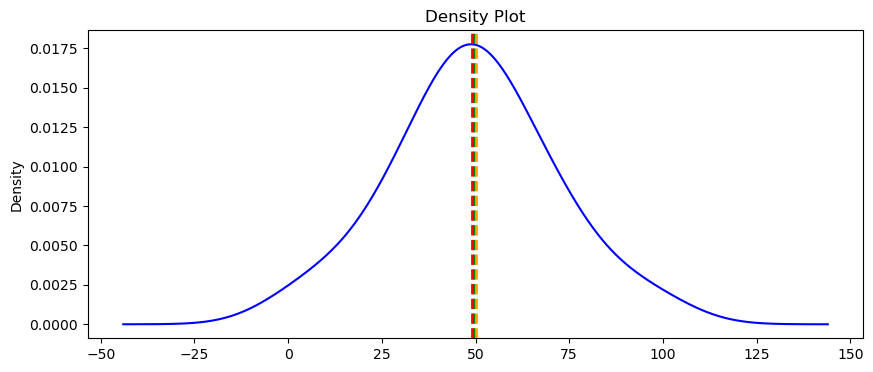

In [24]:
def show_density(var_data):
    from matplotlib import pyplot as plt

    fig = plt.figure(figsize=(10, 4))

    var_data.plot(kind='density', color='blue')
    plt.title('Density Plot')

    plt.axvline(x=var_data.mean(), color='red', linestyle='dashed', linewidth=2)
    plt.axvline(x=var_data.median(), color='green', linestyle='dashed', linewidth=2)
    plt.axvline(x=var_data.mode()[0], color='orange', linestyle='dashed', linewidth=2)

    plt.show()

data = df_students['Grade']
show_density(data)
